**15.071 The AI Edge** · Project 1: Predictive AI · Fall 2026 · MIT Sloan School of Management

Team: Audrey DeVault, Paul Bustarret, Charles Loriot, Sara Alafifi

---

# Which clean-energy projects will actually get built?

## Background

Before a solar farm, wind farm or battery can connect to the US grid, it has to enter an **interconnection queue** run by the regional grid operator. The queue has become a bottleneck. At the end of 2025, about 2,000 GW of projects were waiting, more than the entire US power fleet. Most of them will never be built: of the capacity that entered queues between 2000 and 2020, only about **13%** was operating by the end of 2025 (Berkeley Lab, *Queued Up*).

That matters to an **infrastructure fund that backs early-stage projects**. The fund spends development capital (studies, deposits, land options) long before anyone knows whether a project will be built. Every project that later withdraws is money lost. Today's rule of thumb is crude: assume a flat completion rate, or ignore projects until they sign an interconnection agreement years later, when the rights are far more expensive.

**The prediction task.** On the day a project enters the queue, predict whether it will be **operating within 5 years**. The fund then backs the top *K* projects in each year's cohort, and we measure the result as **wasted development spend per MW that actually gets built**.

This notebook walks through the structured-data (tabular) part of the project step by step:

1. Load and label the data
2. Build features known at entry
3. Set up a temporal validation scheme
4. Climb a ladder of models, from rules of thumb to gradient boosting
5. Compare them, explain what drives the predictions, and check the business impact

All results here are on **validation data only**. The 2019–2020 test cohort is held out and not scored in this notebook.

## Setup

We locate the project folder, then import the standard packages and the project's shared code in `src/queue_risk/`. Data loading, labeling and feature building come from that package, so this notebook and the command-line pipeline (`python -m queue_risk.pipeline`) always use the same data.

In [1]:
import os, sys, time, warnings
from pathlib import Path

# The project root is the folder holding pyproject.toml, found by walking up
# from wherever this notebook is opened.
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
print("Project folder:", ROOT)

Project folder: C:\Users\devault\Documents\ai-edge\Projects\Project1


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

from queue_risk import config, data, evaluate, features, impact
from queue_risk.models import FlatRate, HistoricalRate
from queue_risk.split import rolling_folds, temporal_split

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)

We also set a random seed for the whole notebook to ensure reproducibility.

In [3]:
SEED = config.SEED
np.random.seed(SEED)

## The Queued Up dataset

Berkeley Lab's *Queued Up* file lists every request that entered a US interconnection queue, with data through the end of 2025. Each row is one project: its grid operator (`region`), state and county, technology, size in MW, the date it entered the queue, the point on the grid where it would connect, and its status today (operational, withdrawn, active or suspended).

`data.load_raw_queue()` reads the file and applies the cleaning rules documented in `docs/data_quality.md`: it removes 135 duplicated IDs, sets future dates to missing, and builds a 5-digit county key.

In [4]:
raw = data.load_raw_queue()
print(f"{len(raw):,} queue requests, {raw.shape[1]} columns")
print(f"Entry years {int(raw['q_year'].min())}–{int(raw['q_year'].max())}")
raw["q_status"].value_counts().to_frame("projects")

38,066 queue requests, 34 columns
Entry years 1995–2025


,projects
q_status,
withdrawn,24221
active,8513
operational,4654
suspended,668
unknown,10


The file covers every technology, including gas, coal and nuclear. We keep **new solar, wind and battery projects** entering from 2005 onward, the projects a clean-energy fund would actually look at.

In [5]:
clean = raw[raw["type_1"].isin(config.CLEAN_TYPES)]
print(f"Clean-energy requests: {len(clean):,} ({len(clean) / len(raw):.0%} of the file)")
clean["type_1"].value_counts().to_frame("projects")

Clean-energy requests: 30,714 (81% of the file)


,projects
type_1,
Solar,17856
Wind,6570
Battery,6068
Offshore Wind,220


## Defining the outcome: built within 5 years

The obvious label, *was the project ever built?*, has a problem. Withdrawals happen faster than builds, so among recent projects the ones that have already "resolved" are mostly withdrawals. Recent cohorts would look worse than they really are. This is **right-censoring**.

We use a fixed-horizon label instead:

- **built = 1** if the project reached commercial operation **within 5 years** of entering the queue;
- **built = 0** otherwise: withdrawn, suspended, or still waiting when its 5-year window closed.

Every project whose window has closed gets a label, and nothing is censored. The cost: we can only use projects that entered by the end of 2020, and only the six grid operators that record completion dates (CAISO, ERCOT, MISO, NYISO, PJM, SPP).

A project's **status** decides whether it was built, never a date field alone: 222 withdrawn projects carry an operation date in the file.

In [6]:
projects = data.modeling_table(raw)   # built within config.HORIZON = 5 years
print(f"{len(projects):,} labeled projects, {projects['built'].mean():.1%} built within 5 years")

by_year = projects.groupby("q_year")["built"].agg(projects="size", build_rate="mean")
by_year.T

10,703 labeled projects, 8.2% built within 5 years


q_year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
projects,211.000,328.000,427.000,557.000,384.000,719.000,589.000,197.000,251.000,366.000,550.000,905.000,963.000,1072.000,1462.000,1722.00
build_rate,0.232,0.155,0.066,0.061,0.089,0.074,0.065,0.208,0.191,0.199,0.145,0.103,0.077,0.057,0.046,0.03


The build rate is not stable. It swings between 6% and 23% in the early years, then **falls steadily from 20% (2014 entries) to 3% (2020 entries)**. The queue has been flooded with speculative requests: developers file many applications and keep the few that work out. Any model trained on the past has to cope with this drift. We return to it later.

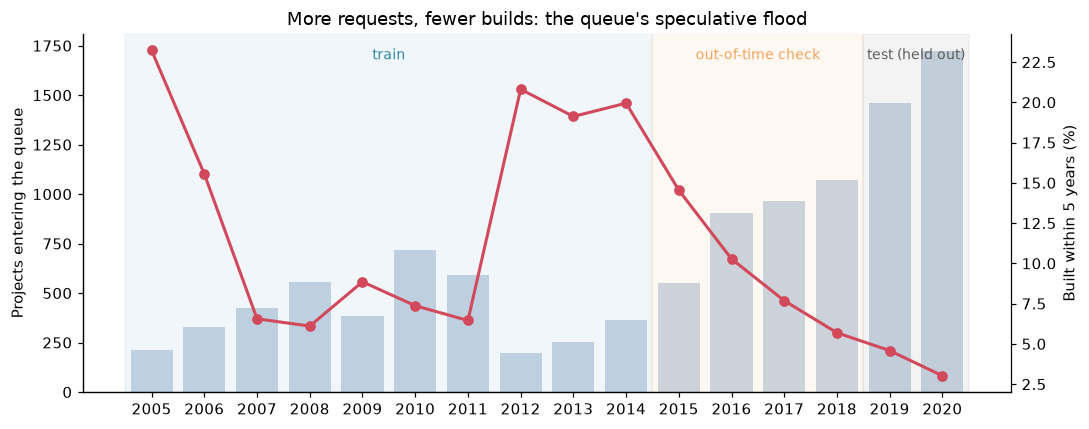

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 4))
years = by_year.index.astype(int)
ax1.bar(years, by_year["projects"], color="#c9d6e3", label="Projects entering")
ax1.set_ylabel("Projects entering the queue")
ax2 = ax1.twinx()
ax2.plot(years, 100 * by_year["build_rate"], color="#d1495b", marker="o", lw=2, label="Built within 5 years")
ax2.set_ylabel("Built within 5 years (%)")
ax2.spines["right"].set_visible(True)
for (a, b), label, color in [((2005, 2014), "train", "#2e86ab"), ((2015, 2018), "out-of-time check", "#f4a259"),
                             ((2019, 2020), "test (held out)", "#5b5b5b")]:
    ax1.axvspan(a - 0.5, b + 0.5, color=color, alpha=0.07)
    ax1.text((a + b) / 2, ax1.get_ylim()[1] * 0.93, label, ha="center", color=color, fontsize=9)
ax1.set_xticks(years)
ax1.set_title("More requests, fewer builds: the queue's speculative flood")
fig.tight_layout()
fig.savefig(FIG / "01_build_rate_by_year.png", bbox_inches="tight")
plt.show()

## Features known at entry

The single most important rule in this project: **only use information an investor would have on the day the project enters the queue.** Study results, the signed interconnection agreement, and the developer's (revisable) proposed online date all arrive later, so using them would leak the answer. `features.build_features()` refuses to run if any of those columns slip in.

We build 26 features in three families:

| Family | Features | Idea |
|---|---|---|
| **Project attributes** | grid operator, state, technology, service type (`NRIS`/`ERIS`), size (log MW), hybrid pairing, entry month | What is being proposed, and where |
| **Track record as of entry** (county, and region × technology) | entries and MW in the past 3 years, projects built and withdrawn **before the entry date**, built share | Lecture 8's *lag variables*: how have earlier projects nearby fared? |
| **Point of interconnection (POI)** | voltage (kV) and line tap vs. substation, parsed from the POI name; the same track-record counts for earlier projects at the same POI | The finest-grained location we have: the exact spot on the grid |

The track-record counts only include projects that were built or withdrawn **strictly before** this project's entry date, so no future information leaks in. A county with no earlier projects has no history; its share stays missing and gets a `county_has_history = 0` flag (the *cold start* problem).

The entry year itself is deliberately **not** a feature. Trees cannot extrapolate to years they have never seen, so time trends enter through the track-record features instead.

In [8]:
X, y = features.build_features(raw, projects)
print(f"X: {X.shape[0]:,} projects × {X.shape[1]} features")
X.head()

X: 10,703 projects × 25 features


,region,type_clean,state,log_mw,is_hybrid,q_month,county_entries_3y,county_mw_3y,county_built_before,county_withdrawn_before,...,region_tech_built_share_before,poi_kv,poi_is_line,poi_is_sub,poi_entries_3y,poi_mw_3y,poi_built_before,poi_withdrawn_before,poi_built_share_before,county_has_history
1780,CAISO,Solar,CA,3.045,0,4,30.0,3109.900,0.0,24.0,...,0.014,115.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,1.0
1783,CAISO,Solar,CA,2.351,0,4,27.0,4761.704,3.0,56.0,...,0.014,230.0,0.0,1.0,0.0,0.0,1.0,3.0,0.25,1.0
1784,CAISO,Solar,CA,1.792,0,1,84.0,13193.522,5.0,143.0,...,0.032,220.0,0.0,1.0,1.0,291.0,0.0,1.0,0.00,1.0
1787,CAISO,Battery,CA,3.045,0,4,0.0,0.000,0.0,0.0,...,NaN,115.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN,0.0
1789,CAISO,Battery,CA,3.045,0,4,1.0,72.000,4.0,10.0,...,NaN,60.0,0.0,1.0,0.0,0.0,0.0,0.0,NaN,1.0


Here is one project, read as an investor would see it on its entry day:

In [9]:
example = projects.query("type_clean == 'Solar' and region == 'ERCOT' and q_year == 2014").index[0]
pd.concat([projects.loc[example, ["project_name", "county", "state", "q_date", "poi_name", "q_status"]],
           X.loc[example]]).to_frame("value")

,value
project_name,Lamesa Solar B (Phase II) IVORY
county,Dawson
state,TX
q_date,2014-06-26 00:00:00
poi_name,1163 Lamesa 138kV
q_status,operational
region,ERCOT
type_clean,Solar
state,TX
log_mw,3.932


Track-record features are missing where there is no history to count, for example the first project at a new point of interconnection. The models fill missing values with the training median and add a "was missing" indicator, so a missing value can carry information of its own.

In [10]:
X.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False).map("{:.1%}".format).to_frame("share missing")

,share missing
poi_built_share_before,84.3%
county_built_share_before,28.3%
poi_kv,20.3%
county_withdrawn_before,5.3%
county_entries_3y,5.3%
county_has_history,5.3%
county_built_before,5.3%
county_mw_3y,5.3%
poi_withdrawn_before,5.2%
poi_mw_3y,5.2%


## Exploratory data analysis

Before fitting models, let's check that the features carry signal. Build rates differ a lot by technology and grid operator. Batteries entering in this period were rarely built within 5 years; ERCOT, Texas's lightly regulated market, builds fastest.

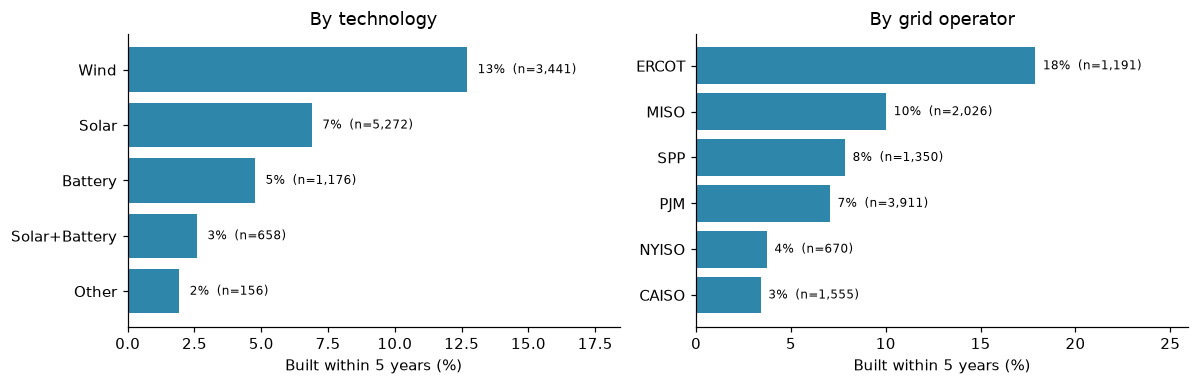

In [11]:
d = projects.assign(tech=projects["type_clean"].where(
        projects["type_clean"].isin(["Solar", "Wind", "Battery", "Solar+Battery"]), "Other"))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, title in [(axes[0], "tech", "By technology"), (axes[1], "region", "By grid operator")]:
    g = d.groupby(col)["built"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(g.index, 100 * g["mean"], color="#2e86ab")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(100 * m + 0.4, i, f"{m:.0%}  (n={n:,})", va="center", fontsize=8)
    ax.set_xlabel("Built within 5 years (%)")
    ax.set_title(title)
    ax.set_xlim(0, 100 * g["mean"].max() * 1.45)
fig.tight_layout()
plt.show()

Track records carry signal too. Where more than half of the earlier projects at the same point of interconnection were built, about 16% of new projects were built within 5 years, double the average. The catch: most projects (84%) are the first resolved project at their POI, so they have no POI history to go on.

In [12]:
share = X["poi_built_share_before"]
bucket = pd.cut(share, [-0.01, 0, 0.25, 0.5, 1.0], labels=["0%", "1–25%", "26–50%", "51–100%"])
bucket = bucket.cat.add_categories("no history").fillna("no history")
t = y.groupby(bucket).agg(["mean", "size"]).rename(columns={"mean": "built within 5y", "size": "projects"})
t.index.name = "earlier projects built at this POI"
t

,built within 5y,projects
earlier projects built at this POI,,
0%,0.062,1081
1–25%,0.025,201
26–50%,0.077,142
51–100%,0.155,252
no history,0.084,9027


## Training, validation and test sets

Our goal is to predict **future** projects, so the split has to follow time, as in the wildfire case (Lecture 6). A random split would let the model learn from 2018 projects to predict 2012 ones.

| Set | Entry years | Purpose |
|---|---|---|
| **Training** | 2005–2014 | Fit and tune every model. Their 5-year outcomes were known by 2019, so a fund could really have built this model in 2019 |
| **Out-of-time check** | 2015–2018 | A harder validation: score years the models never saw, after the queue changed |
| **Test** | 2019–2020 | Held out. Scored **once**, at the end, after the team agrees on the final model |

The 4-year gap between training and test is not wasted: 2015–2018 outcomes were not yet known in 2019, so using them would be cheating.

**Tuning uses rolling-origin cross-validation** (Lecture 4's cross-validation, made temporal). For each year *t* from 2010 to 2014, we fit on all entries **before** *t* and validate on year *t*. This mimics how the model would be used: always predicting the next cohort from the past.

In [13]:
years_all = projects["q_year"].astype(int)
train, test = temporal_split(years_all)             # 2005–2014 / 2019–2020
oot = years_all.between(2015, 2018).to_numpy()      # out-of-time check

Xtr, ytr = X[train], y[train]
Xoot, yoot = X[oot], y[oot]
years_tr = years_all[train].to_numpy()
folds = rolling_folds(years_all[train])             # fit on years < t, validate on t

summary = pd.DataFrame({
    "projects": [train.sum(), oot.sum(), test.sum()],
    "built within 5y": [ytr.mean(), yoot.mean(), y[test].mean()],
}, index=["Training 2005–2014", "Out-of-time 2015–2018", "Test 2019–2020 (held out)"])
summary

,projects,built within 5y
Training 2005–2014,4029,0.111
Out-of-time 2015–2018,3490,0.088
Test 2019–2020 (held out),3184,0.037


In [14]:
pd.DataFrame([{"validate on": int(years_tr[v][0]), "fit on": f"2005–{int(years_tr[v][0]) - 1}",
               "fit projects": len(f), "validation projects": len(v),
               "validation build rate": ytr.iloc[v].mean()} for f, v in folds])

,validate on,fit on,fit projects,validation projects,validation build rate
0,2010,2005–2009,1907,719,0.074
1,2011,2005–2010,2626,589,0.065
2,2012,2005–2011,3215,197,0.208
3,2013,2005–2012,3412,251,0.191
4,2014,2005–2013,3663,366,0.199


## How we measure performance

The fund's decision is a **ranking**: back the most promising *K* projects in each cohort. So we judge models mainly on how well they rank.

- **AUC** (area under the ROC curve, Lecture 3): the probability that a randomly chosen built project is scored above a randomly chosen failed one. 0.5 is a coin flip, 1.0 is perfect. It doesn't depend on any threshold.
- **Precision at K**: the share of the top *K* projects that were actually built. This is the decision metric, since the fund backs *K* projects.
- **Calibration**: do predicted probabilities match observed rates? It matters for dollar estimates, but less for ranking.

The **CV AUC** reported for each model is the mean AUC over the five rolling validation years.

The helper below tunes a model's hyperparameters over the rolling folds with `GridSearchCV`, records the AUC for each validation year, and keeps **out-of-fold predictions**: each 2010–2014 project scored by a model that never saw its year. We use them later for ROC curves and the business impact.

In [15]:
results, oof, searches = {}, {}, {}
val_years = [int(years_tr[v][0]) for _, v in folds]

def run(name, estimator, grid=None):
    t0 = time.time()
    search = GridSearchCV(estimator, grid or {}, cv=folds, scoring="roc_auc", n_jobs=1).fit(Xtr, ytr)
    # Out-of-fold predictions with the selected settings: each year scored by a
    # model fitted only on earlier years.
    p = np.full(len(ytr), np.nan)
    for fit_idx, val_idx in folds:
        m = clone(search.best_estimator_).fit(Xtr.iloc[fit_idx], ytr.iloc[fit_idx])
        p[val_idx] = m.predict_proba(Xtr.iloc[val_idx])[:, 1]
    i = search.best_index_
    by_year = {yr: search.cv_results_[f"split{k}_test_score"][i] for k, yr in enumerate(val_years)}
    results[name] = {"CV AUC": search.best_score_, **by_year,
                     "settings": {k.replace("clf__", ""): v for k, v in search.best_params_.items()}}
    oof[name], searches[name] = p, search
    print(f"{name:34s} CV AUC {search.best_score_:.3f}   ({time.time() - t0:.0f}s)")
    return search

## Benchmark models

Before any machine learning, we set up the two benchmarks the course asks for: a **business rule** and a **predictive baseline**.

### Business rule: a flat completion rate

The simplest rule an investor might use: every project has the same historical chance of being built. It gives every project the same score, so it cannot rank them, and its AUC is 0.5 by construction. Backing *K* projects under this rule is the same as picking at random.

In [16]:
run("Flat rate (rule of thumb)", FlatRate());

Flat rate (rule of thumb)          CV AUC 0.500   (0s)


### Predictive baseline: historical rate by grid operator × technology

A smarter rule of thumb: score each project by the training-period build rate of its grid operator and technology (for example "ERCOT solar"), falling back to the technology average for rare combinations. This is the analogue of Lecture 5's historical baseline, and the bar every model has to clear.

In [17]:
run("Historical rate (region × tech)", HistoricalRate());

Historical rate (region × tech)    CV AUC 0.620   (0s)


## Preprocessing

Every learned model is a scikit-learn `Pipeline`, so the preprocessing is fitted **on the training folds only**:

- **Categorical** features (grid operator, technology, service type, state) are one-hot encoded; categories with fewer than 20 projects are pooled into one "infrequent" column.
- **Numerical** features: missing values are replaced by the median, plus a 0/1 "was missing" indicator. For linear models we also standardize them, so coefficients are comparable and the LASSO penalty treats every feature equally.

These are the same settings as `src/queue_risk/models.py`, so the command-line pipeline reproduces every number below.

In [18]:
CATEGORICAL = features.CATEGORICAL
NUMERIC = [c for c in X.columns if c not in CATEGORICAL]

def make_preprocessor(scale):
    # add_indicator=False matches the repo fix of Nov 15 (blank fields leak the outcome);
    # changed by Audrey/Claude on Nov 24 when refreshing the stale outputs.
    numeric_steps = [SimpleImputer(strategy="median", add_indicator=False)]
    if scale:
        numeric_steps.append(StandardScaler())
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAL),
        ("num", make_pipeline(*numeric_steps), NUMERIC),
    ])

NICE = {
    "log_mw": "Size (log MW)", "is_hybrid": "Hybrid (paired with storage)", "q_month": "Entry month",
    "county_entries_3y": "County: entries, past 3y", "county_mw_3y": "County: MW entered, past 3y",
    "county_built_before": "County: projects built before", "county_withdrawn_before": "County: withdrawn before",
    "county_built_share_before": "County: built share before", "county_has_history": "County has history",
    "region_tech_entries_3y": "Region×tech: entries, past 3y", "region_tech_mw_3y": "Region×tech: MW, past 3y",
    "region_tech_built_before": "Region×tech: built before", "region_tech_withdrawn_before": "Region×tech: withdrawn before",
    "region_tech_built_share_before": "Region×tech: built share before",
    "poi_kv": "POI voltage (kV)", "poi_is_line": "POI is a line tap", "poi_is_sub": "POI is a substation",
    "poi_entries_3y": "POI: entries, past 3y", "poi_mw_3y": "POI: MW entered, past 3y",
    "poi_built_before": "POI: projects built before", "poi_withdrawn_before": "POI: withdrawn before",
    "poi_built_share_before": "POI: built share before",
}

def readable(names):
    # 'num__missingindicator_poi_kv' -> 'POI voltage (kV) missing'; 'cat__region_ERCOT' -> 'region = ERCOT'
    out = []
    for n in names:
        n = n.split("__", 1)[1]
        if n.startswith("missingindicator_"):
            base = n.removeprefix("missingindicator_")
            out.append(NICE.get(base, base) + " missing")
        elif n in NICE:
            out.append(NICE[n])
        else:
            col = next((c for c in CATEGORICAL if n.startswith(c + "_")), None)
            out.append(f"{col} = {n[len(col) + 1:]}" if col else n)
    return out

## Logistic regression

Our first learned model is a logistic regression on all features (Lecture 3). It is interpretable: each coefficient says how a feature shifts the log-odds of being built, holding the others fixed. Because the numerical features are standardized, a coefficient is the effect of a **one-standard-deviation** change.

In [19]:
logit = Pipeline([("prep", make_preprocessor(scale=True)),
                  ("clf", LogisticRegression(max_iter=2000))])
run("Logistic regression", logit);

Logistic regression                CV AUC 0.615   (1s)


The largest coefficients, from the model refitted on all 2005–2014 entries. Positive bars raise the odds of being built within 5 years; negative bars lower them.

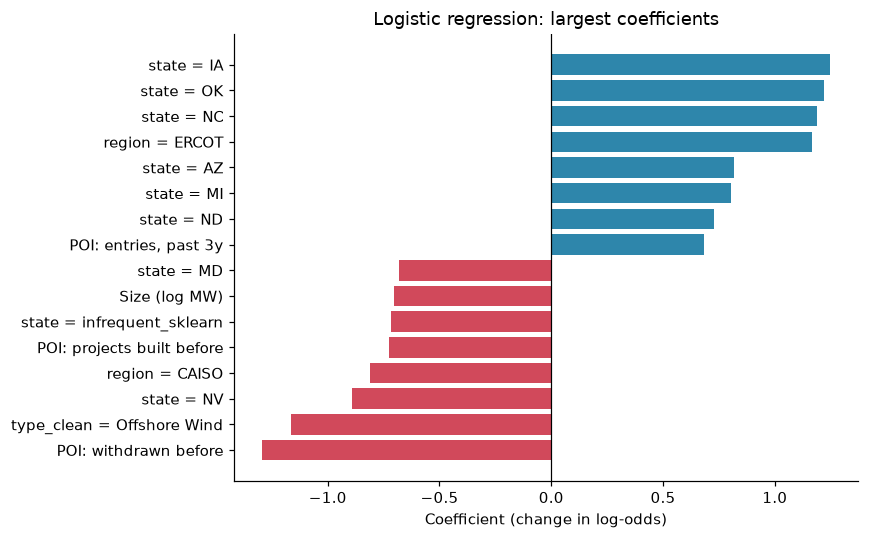

In [20]:
best = searches["Logistic regression"].best_estimator_
coefs = pd.Series(best.named_steps["clf"].coef_[0],
                  index=readable(best.named_steps["prep"].get_feature_names_out()))
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index[:16]).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2e86ab", "#d1495b"))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (change in log-odds)")
ax.set_title("Logistic regression: largest coefficients")
fig.tight_layout()
plt.show()

Read the state and operator coefficients with care. With dozens of correlated dummies, individual coefficients are unstable. That is exactly the problem regularization addresses.

## LASSO logistic regression

The LASSO adds an L1 penalty that shrinks coefficients toward zero and sets many of them exactly to zero (Lecture 4). The strength of the penalty is set by `C`: a **smaller C means a stronger penalty** and a sparser model. We choose `C` by rolling validation.

In [21]:
lasso = Pipeline([("prep", make_preprocessor(scale=True)),
                  ("clf", LogisticRegression(l1_ratio=1.0, solver="saga", max_iter=5000))])
lasso_grid = {"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0]}
run("LASSO logistic", lasso, lasso_grid);

LASSO logistic                     CV AUC 0.631   (59s)


How validation AUC and the number of features kept change with the penalty:

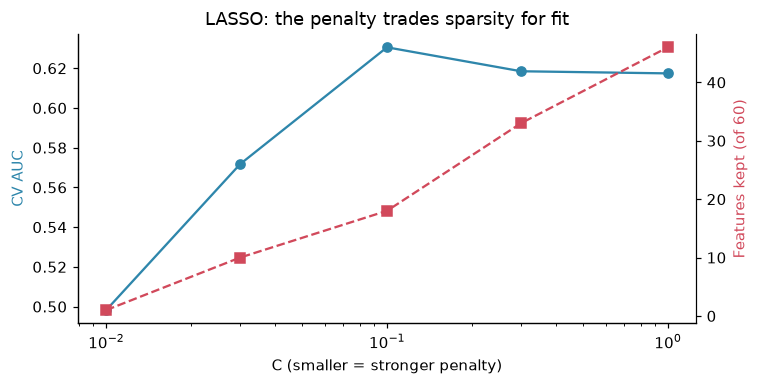

In [22]:
cv = pd.DataFrame(searches["LASSO logistic"].cv_results_)
n_kept = []
for C in lasso_grid["clf__C"]:
    m = clone(lasso).set_params(clf__C=C).fit(Xtr, ytr)
    n_kept.append(int((m.named_steps["clf"].coef_ != 0).sum()))
n_total = len(best.named_steps["prep"].get_feature_names_out())

fig, ax1 = plt.subplots(figsize=(7, 3.6))
ax1.plot(lasso_grid["clf__C"], cv["mean_test_score"], marker="o", color="#2e86ab")
ax1.set_xscale("log"); ax1.set_xlabel("C (smaller = stronger penalty)"); ax1.set_ylabel("CV AUC", color="#2e86ab")
ax2 = ax1.twinx(); ax2.spines["right"].set_visible(True)
ax2.plot(lasso_grid["clf__C"], n_kept, marker="s", ls="--", color="#d1495b")
ax2.set_ylabel(f"Features kept (of {n_total})", color="#d1495b")
ax1.set_title("LASSO: the penalty trades sparsity for fit")
fig.tight_layout()
plt.show()

The strongest penalty (`C = 0.01`) throws away too much. Validation picks a moderate penalty that beats the plain logistic regression while dropping a share of the dummies.

## Classification tree (CART)

A decision tree (Lecture 5) splits projects into groups with simple yes/no rules. It captures interactions automatically, for example "solar in ERCOT at a POI with past builds", with no need to specify them. Its complexity is controlled by the cost-complexity parameter `ccp_alpha` (larger means more pruning, so a smaller tree) and by a minimum of 50 projects per leaf.

In [23]:
cart = Pipeline([("prep", make_preprocessor(scale=False)),
                 ("clf", DecisionTreeClassifier(min_samples_leaf=50, random_state=SEED))])
cart_grid = {"clf__ccp_alpha": [1e-4, 3e-4, 1e-3, 3e-3]}
run("CART", cart, cart_grid)

cv = pd.DataFrame(searches["CART"].cv_results_)
cv[["param_clf__ccp_alpha", "mean_test_score", "std_test_score"]].rename(
    columns={"param_clf__ccp_alpha": "ccp_alpha", "mean_test_score": "CV AUC", "std_test_score": "std across years"})

CART                               CV AUC 0.593   (1s)


,ccp_alpha,CV AUC,std across years
0,1.000e-04,0.587,0.066
1,3.000e-04,0.593,0.074
2,1.000e-03,0.584,0.059
3,3.000e-03,0.532,0.051


The selected tree is too large to read. For illustration, here is a **shallow tree of depth 3**, fitted on all training years. Each box shows the rule, the number of projects, and the share built within 5 years (`value`, the second number).

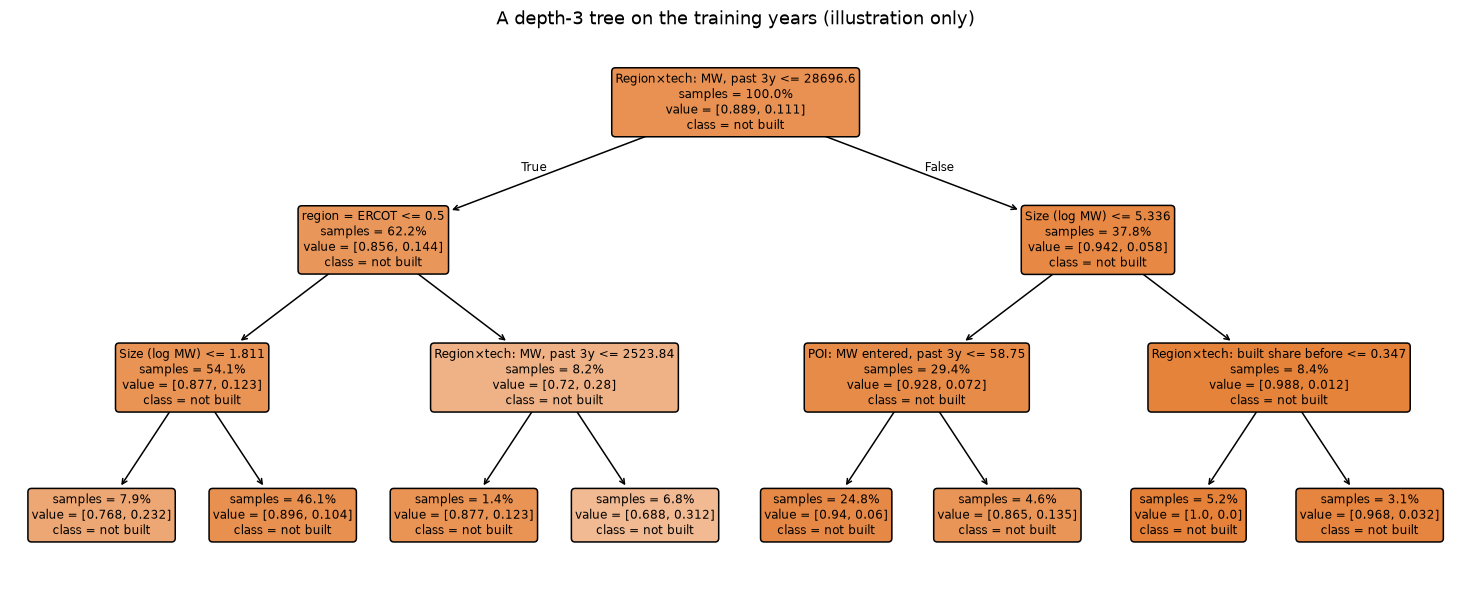

In [24]:
shallow = Pipeline([("prep", make_preprocessor(scale=False)),
                    ("clf", DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED))]).fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(17, 6.5))
plot_tree(shallow.named_steps["clf"], feature_names=readable(shallow.named_steps["prep"].get_feature_names_out()),
          class_names=["not built", "built"], filled=True, impurity=False, proportion=True,
          rounded=True, fontsize=8, ax=ax)
ax.set_title("A depth-3 tree on the training years (illustration only)")
plt.show()

## Random forest

A single tree is unstable: small changes in the data can produce a very different tree. A random forest (Lecture 6) averages **500 trees**, each grown on a bootstrap sample of the projects and allowed to consider only a random subset of features at each split. We tune the tree depth and the share of features considered at each split.

In [25]:
rf = Pipeline([("prep", make_preprocessor(scale=False)),
               ("clf", RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED))])
rf_grid = {"clf__max_depth": [6, 10, None], "clf__max_features": [0.25, 0.5]}
run("Random forest", rf, rf_grid)

cv = pd.DataFrame(searches["Random forest"].cv_results_)
cv.pivot_table(index="param_clf__max_depth", columns="param_clf__max_features", values="mean_test_score",
               dropna=False).rename_axis(index="max_depth", columns="max_features")

Random forest                      CV AUC 0.629   (73s)


max_features,0.25,0.50
max_depth,,
6.0,0.629,0.616
10.0,0.626,0.615
NaN,0.600,0.601


Shallow trees (depth 6) do best. With only about 4,000 training projects and a drifting target, deeper trees memorize noise from particular years.

Feature importance (mean decrease in impurity) shows which features the forest relies on most:

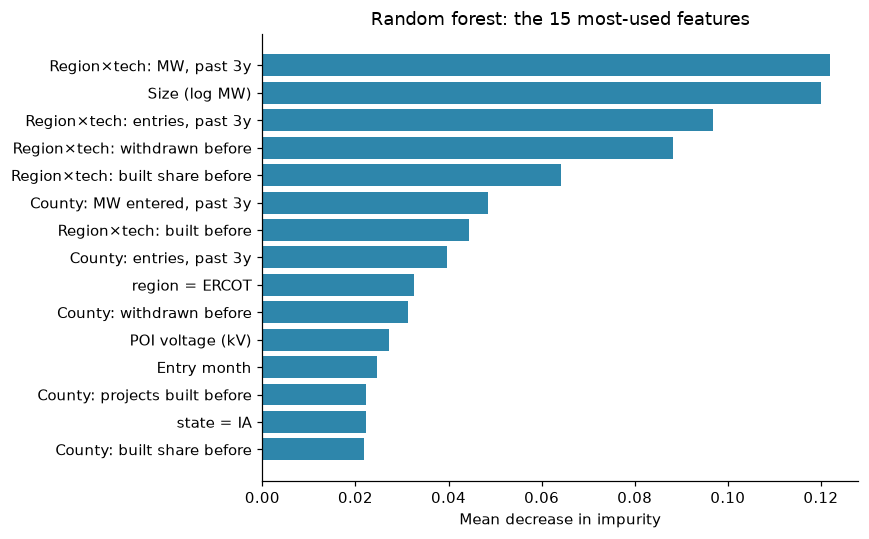

In [26]:
best = searches["Random forest"].best_estimator_
imp = pd.Series(best.named_steps["clf"].feature_importances_,
                index=readable(best.named_steps["prep"].get_feature_names_out())).sort_values().tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color="#2e86ab")
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Random forest: the 15 most-used features")
fig.tight_layout()
plt.show()

## Gradient boosting

Gradient boosting (Lecture 6) builds trees **sequentially**: each new tree corrects the errors of the ones before it. It is usually the strongest default for tabular data. We use scikit-learn's `HistGradientBoostingClassifier`, which bins the features for speed and handles missing values natively, and tune the learning rate, the depth of each tree and the number of trees.

In [27]:
gb = Pipeline([("prep", make_preprocessor(scale=False)),
               ("clf", HistGradientBoostingClassifier(random_state=SEED))])
gb_grid = {"clf__learning_rate": [0.03, 0.1], "clf__max_depth": [2, 4, None], "clf__max_iter": [200, 500]}
run("Gradient boosting", gb, gb_grid)

cv = pd.DataFrame(searches["Gradient boosting"].cv_results_)
cv.pivot_table(index=["param_clf__learning_rate", "param_clf__max_iter"], columns="param_clf__max_depth",
               values="mean_test_score", dropna=False).rename_axis(
    index=["learning rate", "trees"], columns="max depth")

Gradient boosting                  CV AUC 0.663   (85s)


max depth              2.0    4.0    NaN
learning rate trees                     
0.03          200    0.631  0.661  0.659
              500    0.647  0.663  0.653
0.10          200    0.642  0.645  0.649
              500    0.651  0.636  0.641

The winning settings are deliberately conservative: a low learning rate with shallow trees. As with the forest, the drifting queue rewards simple models that don't chase patterns specific to one year.

## Model comparison

We now compare all models on the rolling validation years.

In [28]:
table = pd.DataFrame(results).T
table.index.name = "model"
table[["CV AUC", *val_years, "settings"]]

,CV AUC,2010,2011,2012,2013,2014,settings
model,,,,,,,
Flat rate (rule of thumb),0.5,0.5,0.5,0.5,0.5,0.5,{}
Historical rate (region × tech),0.62,0.474,0.623,0.674,0.728,0.599,{}
Logistic regression,0.615,0.58,0.558,0.739,0.627,0.571,{}
LASSO logistic,0.631,0.541,0.644,0.709,0.665,0.593,{'C': 0.1}
CART,0.593,0.573,0.504,0.726,0.601,0.561,{'ccp_alpha': 0.0003}
Random forest,0.629,0.532,0.589,0.679,0.74,0.604,"{'max_depth': 6, 'max_features': 0.25}"
Gradient boosting,0.663,0.574,0.719,0.744,0.681,0.595,"{'learning_rate': 0.03, 'max_depth': 4, 'max_i..."


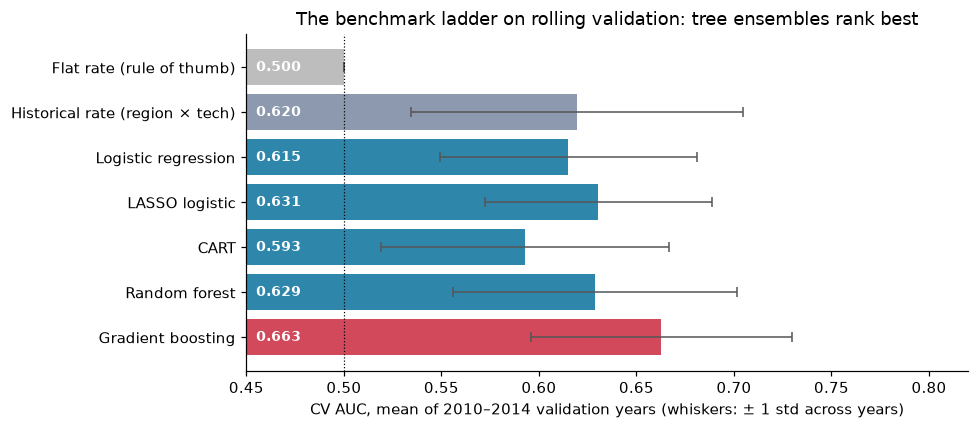

In [29]:
names = list(results)
cv_auc = [results[n]["CV AUC"] for n in names]
spread = [np.std([results[n][yr] for yr in val_years]) for n in names]
colors = ["#bdbdbd", "#8d99ae"] + ["#2e86ab"] * (len(names) - 3) + ["#d1495b"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(names[::-1], cv_auc[::-1], xerr=spread[::-1], color=colors[::-1], capsize=3,
        error_kw={"ecolor": "#555555", "lw": 1})
for i, v in enumerate(cv_auc[::-1]):
    ax.text(0.455, i, f"{v:.3f}", va="center", fontsize=9, color="white", fontweight="bold")
ax.axvline(0.5, color="black", lw=0.8, ls=":")
ax.set_xlim(0.45, 0.82)
ax.set_xlabel("CV AUC, mean of 2010–2014 validation years (whiskers: ± 1 std across years)")
ax.set_title("The benchmark ladder on rolling validation: tree ensembles rank best")
fig.tight_layout()
fig.savefig(FIG / "02_model_comparison.png", bbox_inches="tight")
plt.show()

The ROC curves, from the out-of-fold predictions pooled over 2010–2014, tell the same story:

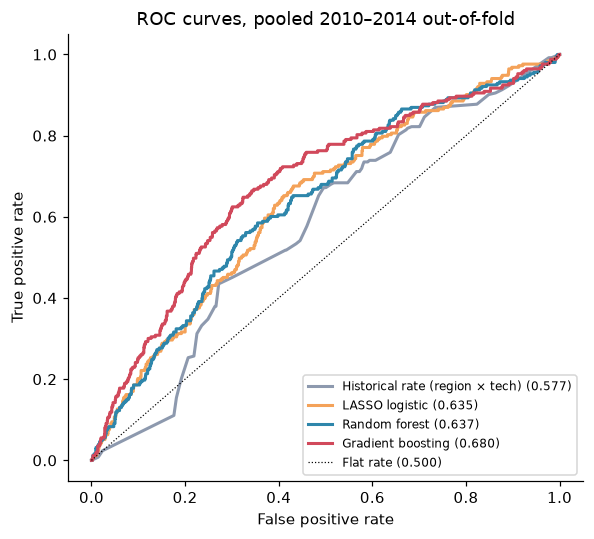

In [30]:
val = ~np.isnan(oof["Gradient boosting"])
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, color in [("Historical rate (region × tech)", "#8d99ae"), ("LASSO logistic", "#f4a259"),
                    ("Random forest", "#2e86ab"), ("Gradient boosting", "#d1495b")]:
    fpr, tpr, _ = roc_curve(ytr[val], oof[name][val])
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} ({roc_auc_score(ytr[val], oof[name][val]):.3f})")
ax.plot([0, 1], [0, 1], color="black", lw=0.8, ls=":", label="Flat rate (0.500)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves, pooled 2010–2014 out-of-fold")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

*Updated Nov 24 (Audrey/Claude): numbers refreshed after the Nov 15 blank-field leakage fix; Charles's structure kept.*

On rolling validation, **gradient boosting** has the best CV AUC (0.663). The LASSO (0.631) and the random forest (0.629) are next, just above the historical-rate baseline (0.620); plain logistic regression (0.615) and CART (0.593) fall below it. All beat the flat rule (0.500).

Two cautions before crowning a winner:
- **The gaps are small** next to the year-to-year spread across validation years (cell above).
- **Validation stays inside the 2005–2014 era.** The section after next checks how the models hold up on later cohorts, and that check changes the pick.

Validation alone would pick gradient boosting. The out-of-time check below is why the team's headline model is the LASSO.

## What drives the predictions? SHAP values

Feature importance says *which* features matter, but not *in which direction*. **SHAP values** split each project's prediction into one contribution per feature. In the plot below, each dot is a training project:

- its horizontal position is how much that feature pushed the prediction up or down (in log-odds);
- its color is the feature's value (red = high, blue = low).

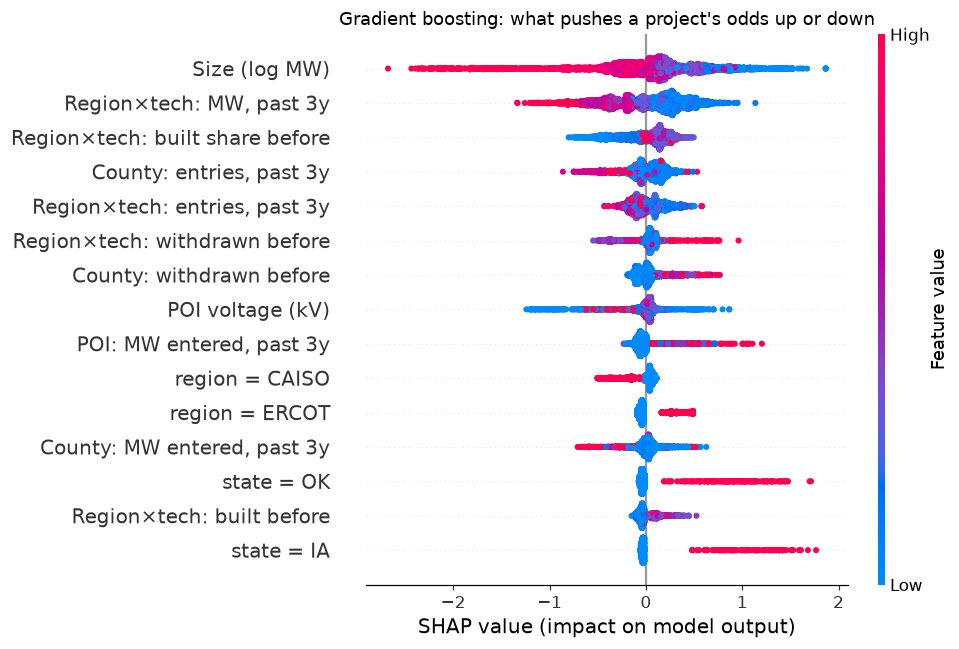

In [31]:
import shap

best = searches["Gradient boosting"].best_estimator_
prep, clf = best.named_steps["prep"], best.named_steps["clf"]
Xt = prep.transform(Xtr)
Xt = Xt.toarray() if hasattr(Xt, "toarray") else Xt
sv = shap.TreeExplainer(clf).shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else sv

shap.summary_plot(sv, Xt, feature_names=readable(prep.get_feature_names_out()), max_display=15,
                  show=False, plot_size=(9, 6))
plt.title("Gradient boosting: what pushes a project's odds up or down")
plt.tight_layout()
plt.savefig(FIG / "03_shap_drivers.png", bbox_inches="tight")
plt.show()

What the model has learned:

- **Project size:** larger projects (red dots) are *less* likely to be built within 5 years. Big projects take longer and need more network upgrades.
- **Regional context:** a strong build record for the same grid operator and technology raises the odds; a crowded queue (many MW entered in the past 3 years) lowers them.
- **Specific operators and states:** CAISO projects score lower; some states (Iowa, Oklahoma) score higher.

These are **associations, not causes**. A region with past builds probably has spare transmission capacity, and that is what the model picks up.

**A data caveat worth flagging to the team.** Two of the strongest drivers are *missing-value flags*, not real project information:
- **Missing POI name** (top row): it lowers the odds sharply.
- **Missing state:** it raises them.

The next cell looks at where these rows come from.

In [32]:
flags = pd.DataFrame({"state missing": X["state"].isna(), "POI name missing": X["poi_entries_3y"].isna()})
era = pd.cut(years_all, [2004, 2014, 2018, 2020], labels=["2005–2014 (train)", "2015–2018", "2019–2020 (test)"])
rows = []
for f in flags:
    m = flags[f]
    rows.append({"flag": f, "rows": int(m.sum()),
                 "mostly in": projects.loc[m, "region"].value_counts().head(2).to_dict(),
                 "built within 5y (flagged)": y[m].mean(), "built within 5y (others)": y[~m].mean(),
                 **{f"share of {e}": m[era == e].mean() for e in era.cat.categories}})
pd.DataFrame(rows).set_index("flag").style.format(
    {c: "{:.1%}" for c in ["built within 5y (flagged)", "built within 5y (others)"]
     + [f"share of {e}" for e in era.cat.categories]})

,rows,mostly in,built within 5y (flagged),built within 5y (others),share of 2005–2014 (train),share of 2015–2018,share of 2019–2020 (test)
flag,,,,,,,
state missing,3,"{'MISO': 1, 'PJM': 1}",33.3%,8.2%,0.0%,0.1%,0.0%
POI name missing,559,"{'ERCOT': 300, 'SPP': 218}",2.7%,8.5%,11.2%,1.5%,1.8%


- **Missing state:** almost all of these rows are older ERCOT projects, where the state is obviously Texas. The flag works as a marker for "early ERCOT project". It describes how the data was recorded, not anything an investor would learn.
- **Missing POI name:** about 9 in 10 of these projects withdrew. If grid operators blank the connection point after a withdrawal, this flag carries information from *after* entry, which is **leakage**.

Both flags cover about 10% of training rows but only 1–2% of later cohorts. The model leans on a pattern that disappears in later years, which may be part of why it transfers poorly (next section).

**Suggested fix (a team decision):** fill the state from the operator where it is obvious (ERCOT → TX), drop the POI-missing indicator, then rerun the validation.

## Calibration: do the probabilities add up?

The fund ranks projects, but dollar estimates need probabilities that match reality. We compare the average predicted probability with the observed build rate, by decile of predicted probability (out-of-fold, 2010–2014).

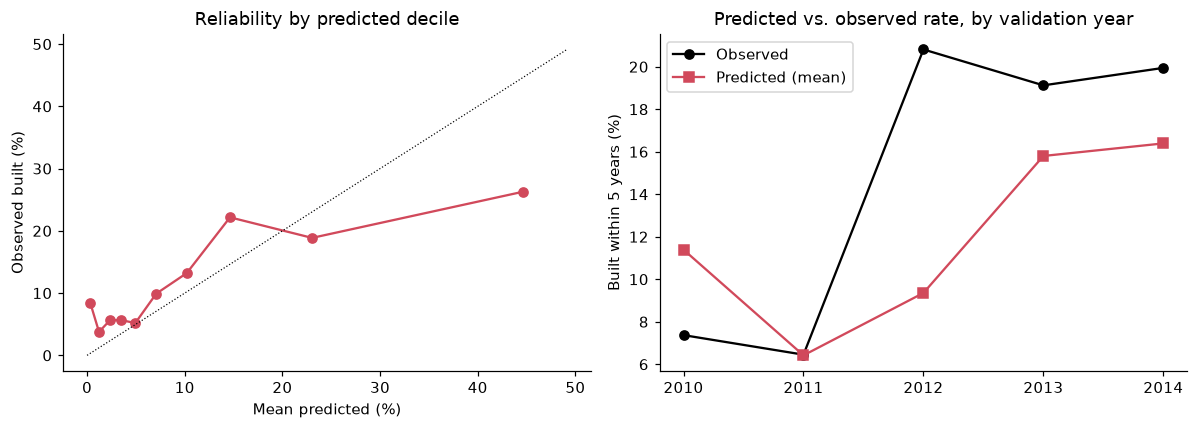

In [33]:
p_gb = oof["Gradient boosting"][val]
rel = evaluate.reliability_table(ytr[val].to_numpy(), p_gb)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.plot(100 * rel["predicted"], 100 * rel["observed"], marker="o", color="#d1495b")
lim = 100 * max(rel["predicted"].max(), rel["observed"].max()) * 1.1
ax.plot([0, lim], [0, lim], color="black", lw=0.8, ls=":")
ax.set_xlabel("Mean predicted (%)"); ax.set_ylabel("Observed built (%)")
ax.set_title("Reliability by predicted decile")

ax = axes[1]
by = pd.DataFrame({"year": years_tr[val], "y": ytr[val].to_numpy(), "p": p_gb}).groupby("year").mean()
ax.plot(by.index, 100 * by["y"], marker="o", label="Observed", color="black")
ax.plot(by.index, 100 * by["p"], marker="s", label="Predicted (mean)", color="#d1495b")
ax.set_xticks(by.index); ax.set_ylabel("Built within 5 years (%)")
ax.set_title("Predicted vs. observed rate, by validation year")
ax.legend()
fig.tight_layout()
plt.show()

The **ranking** holds (higher deciles are built more often), but the **levels drift**. Each validation year is predicted from earlier years, and the build rate jumps from about 6% for 2011 entries to about 20% for 2012–2014 entries. A model can't foresee that. In practice, the probabilities should be recalibrated on the most recent closed cohort before quoting dollar figures, while the ranking can be used as is.

## A harder check: scoring 2015–2018 out of time

Rolling validation stays inside 2005–2014. The real test cohort (2019–2020) sits after the queue's speculative flood began, so we run a tougher check first: fit each model on **all 2005–2014 entries** and score the **2015–2018** cohorts, which no model has seen. This is still validation; the test cohort remains untouched.

In [34]:
oot_years = years_all[oot].to_numpy()
oot_rows, oot_scores = [], {}
for name in names:
    p = searches[name].best_estimator_.predict_proba(Xoot)[:, 1]
    oot_scores[name] = p
    row = {"model": name, "AUC 2015–2018": roc_auc_score(yoot, p)}
    row.update({yr: roc_auc_score(yoot[oot_years == yr], p[oot_years == yr]) for yr in range(2015, 2019)})
    oot_rows.append(row)
oot_table = pd.DataFrame(oot_rows).set_index("model")
oot_table

,AUC 2015–2018,2015,2016,2017,2018
model,,,,,
Flat rate (rule of thumb),0.500,0.500,0.500,0.500,0.500
Historical rate (region × tech),0.593,0.592,0.578,0.599,0.597
Logistic regression,0.641,0.612,0.623,0.603,0.671
LASSO logistic,0.686,0.627,0.637,0.668,0.737
CART,0.610,0.597,0.612,0.615,0.543
Random forest,0.588,0.682,0.564,0.534,0.524
Gradient boosting,0.633,0.635,0.628,0.594,0.605


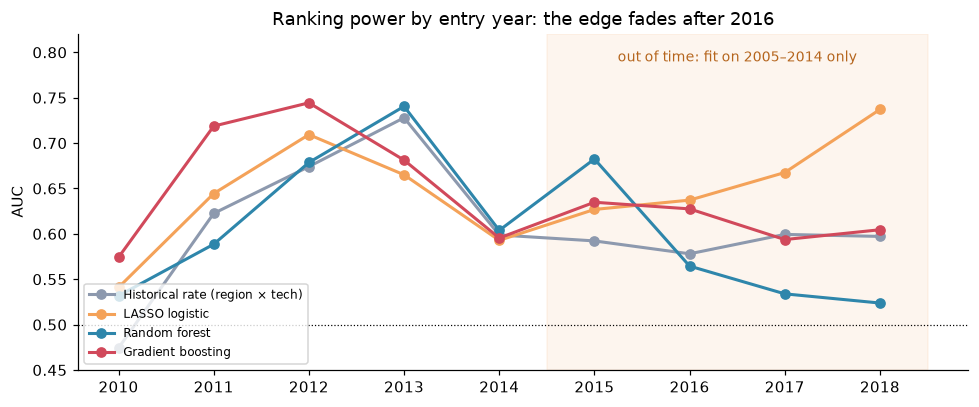

In [35]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for name, color in [("Historical rate (region × tech)", "#8d99ae"), ("LASSO logistic", "#f4a259"),
                    ("Random forest", "#2e86ab"), ("Gradient boosting", "#d1495b")]:
    yrs = val_years + list(range(2015, 2019))
    auc = [results[name][yr] for yr in val_years] + [oot_table.loc[name, yr] for yr in range(2015, 2019)]
    ax.plot(yrs, auc, marker="o", color=color, lw=2, label=name)
ax.axvspan(2014.5, 2018.5, color="#f4a259", alpha=0.1)
ax.text(2016.5, 0.79, "out of time: fit on 2005–2014 only", ha="center", fontsize=9, color="#b5651d")
ax.axhline(0.5, color="black", lw=0.8, ls=":")
ax.set_ylim(0.45, 0.82); ax.set_ylabel("AUC"); ax.set_xticks(yrs)
ax.set_title("Ranking power by entry year: the edge fades after 2016")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "04_auc_by_year.png", bbox_inches="tight")
plt.show()

*Updated Nov 24 (Audrey/Claude): numbers refreshed after the Nov 15 blank-field leakage fix; Charles's structure kept.*

This may be the most important finding for the pitch.

- **The ranking reshuffles out of time.** The **LASSO** holds up best (AUC 0.686). Logistic regression is next (0.641), then gradient boosting (0.633) and CART (0.610). The random forest falls below the historical-rate baseline (0.588 vs. 0.593). The flexible models learned patterns specific to 2005–2014 that don't carry over as well.
- **The LASSO doesn't fade on recent cohorts.** It scores 0.668 on 2017 entries and 0.737 on 2018, while gradient boosting gets 0.594 / 0.605 and the random forest about 0.53. (Before the leakage fix, every model looked like a coin flip on 2017–2018. That was largely the leak, which lived in old resolved records.)

How fragile is the choice among near-identical models? The next cell refits all 12 gradient-boosting settings from the tuning grid. On rolling validation they span 0.63–0.66.

In [36]:
gb_rows = []
for params in searches["Gradient boosting"].cv_results_["params"]:
    m = clone(gb).set_params(**params).fit(Xtr, ytr)
    gb_rows.append({"learning rate": params["clf__learning_rate"], "max depth": params["clf__max_depth"],
                    "trees": params["clf__max_iter"]})
    gb_rows[-1]["Out-of-time AUC 2015–2018"] = roc_auc_score(yoot, m.predict_proba(Xoot)[:, 1])
sens = pd.DataFrame(gb_rows)
sens["CV AUC 2010–2014"] = searches["Gradient boosting"].cv_results_["mean_test_score"]
sens.sort_values("CV AUC 2010–2014", ascending=False).reset_index(drop=True)

,learning rate,max depth,trees,Out-of-time AUC 2015–2018,CV AUC 2010–2014
0,0.03,4.0,500,0.633,0.663
1,0.03,4.0,200,0.641,0.661
2,0.03,NaN,200,0.621,0.659
3,0.03,NaN,500,0.614,0.653
4,0.10,2.0,500,0.626,0.651
5,0.10,NaN,200,0.632,0.649
6,0.03,2.0,500,0.639,0.647
7,0.10,4.0,200,0.624,0.645
8,0.10,2.0,200,0.631,0.642
9,0.10,NaN,500,0.615,0.641


*Updated Nov 24 (Audrey/Claude): numbers refreshed after the Nov 15 blank-field leakage fix; Charles's structure kept.*

Settings that look similar on rolling validation range from about 0.61 to 0.65 out of time. The one validation picks (0.663 on validation) lands mid-pack at 0.633, and none of them reaches the LASSO's 0.686.

Two lessons for the project:
1. **Choosing a model under drift is fragile.** Validation inside one era doesn't reliably pick the model that works in the next. A regularized linear model (LASSO) is the safer bet, so it's the headline model for the test run.
2. **Reconciled since:** the README used to pair a validation number with an out-of-time number from a different gradient-boosting setting. The pipeline now reports both for the same selected configuration, and the test run uses the frozen settings in `src/queue_risk/frozen.py`.

Either way, a model like this needs **regular refreshing** on the latest closed cohorts.

## Does it matter? Backing the top K projects

Now the business question. Each year, the fund backs **K = 25** projects from the new cohort and pays development costs on each one. We compare ways of choosing them:

- **Random**, which is what the flat-rate rule amounts to, since it can't tell projects apart. We use its *expected* result, which is simply the cohort's base rate, so one lucky or unlucky draw doesn't decide the comparison;
- the **historical rate** by grid operator × technology;
- the **LASSO** and **gradient boosting** models.

For each rule we measure the **share of backed MW built within 5 years**. No year is scored by a model that saw it: 2010–2014 use the out-of-fold scores, and 2015–2018 the out-of-time scores.

In [37]:
K = 25
cost = config.DEV_COST_RANGE_USD[1]          # placeholder mid value, $3M per project (not yet sourced)
mw_all = projects["mw_total"].fillna(0).to_numpy()
RULES = {"Historical rate": "Historical rate (region × tech)", "LASSO": "LASSO logistic",
         "Gradient boosting": "Gradient boosting"}

cohorts = []   # (year, era, outcomes, MW, {rule: scores})
for yr in val_years:
    i = val & (years_tr == yr)
    cohorts.append((yr, "rolling validation", ytr[i].to_numpy(), mw_all[train][i],
                    {r: oof[m][i] for r, m in RULES.items()}))
for yr in range(2015, 2019):
    i = oot_years == yr
    cohorts.append((yr, "out of time", yoot[i].to_numpy(), mw_all[oot][i],
                    {r: oot_scores[m][i] for r, m in RULES.items()}))

def mw_hit_rate(yy, mw, scores, k):
    idx = impact.backed(scores, k)
    return (mw[idx] * yy[idx]).sum() / mw[idx].sum()

rows = []
for yr, era_name, yy, mw, scores in cohorts:
    row = {"year": yr, "era": era_name, "cohort": len(yy), "Random (base rate)": (mw * yy).sum() / mw.sum()}
    row.update({r: mw_hit_rate(yy, mw, s, K) for r, s in scores.items()})
    rows.append(row)
topk = pd.DataFrame(rows).set_index("year")
rate_cols = ["Random (base rate)", *RULES]

print(f"Share of backed MW built within 5 years, backing the top {K} projects of each cohort")
show = topk.copy()
show[rate_cols] = show[rate_cols].map("{:.0%}".format)
show

Share of backed MW built within 5 years, backing the top 25 projects of each cohort


,era,cohort,Random (base rate),Historical rate,LASSO,Gradient boosting
year,,,,,,
2010,rolling validation,719,4%,3%,14%,21%
2011,rolling validation,589,4%,19%,7%,17%
2012,rolling validation,197,18%,51%,41%,46%
2013,rolling validation,251,19%,11%,30%,35%
2014,rolling validation,366,23%,3%,24%,84%
2015,out of time,550,20%,8%,56%,28%
2016,out of time,905,10%,1%,37%,49%
2017,out of time,963,8%,0%,24%,2%
2018,out of time,1072,4%,1%,23%,0%


In [38]:
lift = topk.groupby("era", sort=False)[rate_cols].mean()
lift = lift.div(lift["Random (base rate)"], axis=0)
print("Average hit rate relative to random (1.0 = no better than random), by era")
lift.round(2)

Average hit rate relative to random (1.0 = no better than random), by era


,Random (base rate),Historical rate,LASSO,Gradient boosting
era,,,,
rolling validation,1.0,1.31,1.75,3.02
out of time,1.0,0.23,3.33,1.90


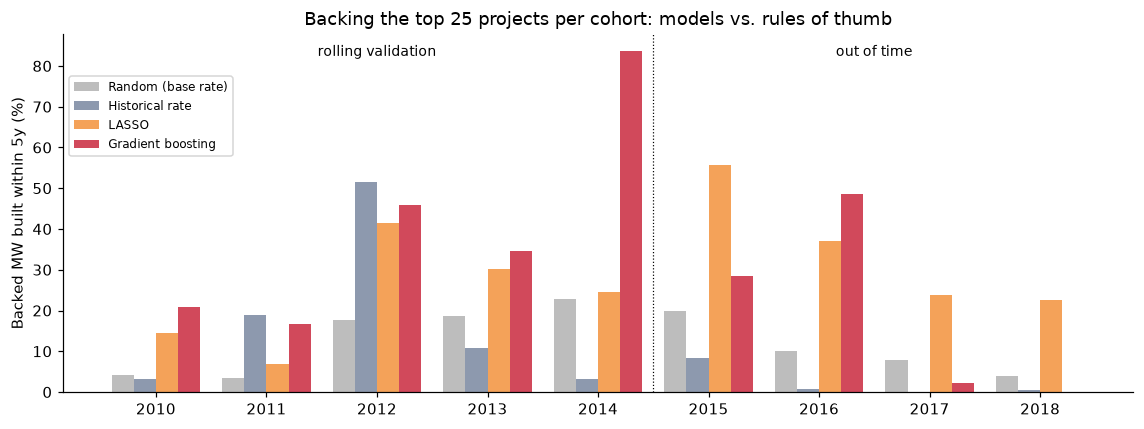

In [39]:
fig, ax = plt.subplots(figsize=(10.5, 4))
w = 0.2
xs = np.arange(len(topk))
for j, (rule, color) in enumerate([("Random (base rate)", "#bdbdbd"), ("Historical rate", "#8d99ae"),
                                   ("LASSO", "#f4a259"), ("Gradient boosting", "#d1495b")]):
    ax.bar(xs + (j - 1.5) * w, 100 * topk[rule], w, color=color, label=rule)
ax.axvline(4.5, color="black", lw=0.8, ls=":")
top = ax.get_ylim()[1]
ax.text(2, top * 0.97, "rolling validation", ha="center", va="top", fontsize=9)
ax.text(6.5, top * 0.97, "out of time", ha="center", va="top", fontsize=9)
ax.set_xticks(xs, topk.index)
ax.set_ylabel("Backed MW built within 5y (%)")
ax.set_title(f"Backing the top {K} projects per cohort: models vs. rules of thumb")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.9))
fig.tight_layout()
fig.savefig(FIG / "05_top25_hit_rate.png", bbox_inches="tight")
plt.show()

In the rolling-validation years, the gradient-boosting top 25 had 13–78% of their MW built within 5 years, against 4–23% for random picks. That's **about 4× better** (LASSO about 3×).

Out of time, the gain shrinks to **about 1.4×**, and all of it comes from 2015–2016. In 2017–2018, the top 25 do no better than random. The historical-rate rule does *worse* than random out of time: the region-technology cells it favoured stopped delivering.

### Wasted development spend per built MW

The project's headline metric: **wasted spend per built MW** = (cost per project × number of backed projects that failed) ÷ (MW of backed projects that were built). Lower is better. We sweep *K*, the number of projects backed per year, and add up the cohorts within each era.

**How to rank for this metric.** The fund pays a fixed development cost *per project*, but the payoff is *MW built*. A 20 MW project and a 300 MW project cost the same to back, but only one adds much capacity. So the right ranking is **expected built MW = probability × size**, not the probability alone. We show both, plus the obvious rule of thumb "back the biggest projects first", which ignores the probability.

The cost per project is a **placeholder** (`config.DEV_COST_RANGE_USD`, mid value $3M) until it is sourced. Every rule is charged the same cost per project, so the **ratio** between rules doesn't depend on it; only the dollar scale does. Perfect hindsight is left off: it wastes $0 until *K* exceeds the number of projects actually built.

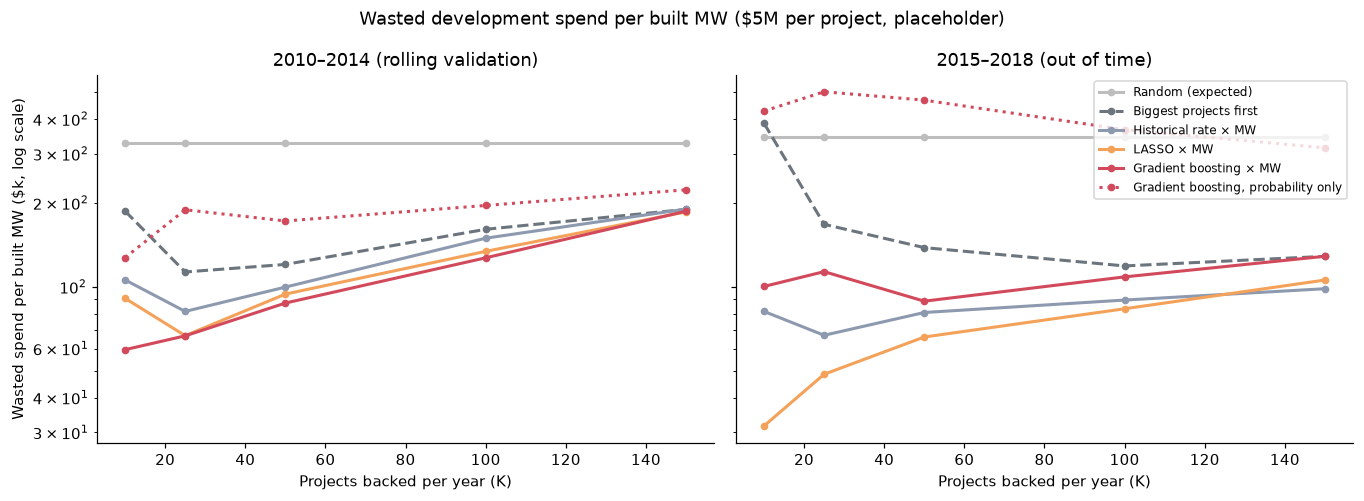

In [40]:
ks = [10, 25, 50, 100, 150]

# Each rule turns a cohort's model scores and MW into a ranking score.
RANK = {
    "Random (expected)": None,
    "Biggest projects first": lambda sc, mw: mw,
    "Historical rate × MW": lambda sc, mw: sc["Historical rate"] * mw,
    "LASSO × MW": lambda sc, mw: sc["LASSO"] * mw,
    "Gradient boosting × MW": lambda sc, mw: sc["Gradient boosting"] * mw,
    "Gradient boosting, probability only": lambda sc, mw: sc["Gradient boosting"],
}
STYLE = {"Random (expected)": ("#bdbdbd", "-"), "Biggest projects first": ("#6c757d", "--"),
         "Historical rate × MW": ("#8d99ae", "-"), "LASSO × MW": ("#f4a259", "-"),
         "Gradient boosting × MW": ("#d1495b", "-"), "Gradient boosting, probability only": ("#d1495b", ":")}

def wasted_per_built_mw(era_name, rule):
    out = []
    for k in ks:
        wasted = built = 0.0
        for yr, e, yy, mw, scores in cohorts:
            if e != era_name:
                continue
            ke = min(k, len(yy))
            if RANK[rule] is None:                     # expected value of a random pick
                wasted += cost * ke * (1 - yy.mean())
                built += ke * (mw * yy).mean()
            else:
                r = impact.portfolio(yy, mw, RANK[rule](scores, mw), ke, cost)
                wasted += r["wasted_usd"]
                built += r["mw_built"]
        out.append(wasted / built / 1e3 if built else np.nan)   # $ thousands per built MW
    return out

curves = {e: pd.DataFrame({r: wasted_per_built_mw(e, r) for r in RANK}, index=pd.Index(ks, name="K"))
          for e in ["rolling validation", "out of time"]}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
for ax, (e, label) in zip(axes, [("rolling validation", "2010–2014 (rolling validation)"),
                                 ("out of time", "2015–2018 (out of time)")]):
    for rule, (color, ls) in STYLE.items():
        ax.plot(ks, curves[e][rule], marker="o", ms=4, color=color, ls=ls, lw=2, label=rule)
    ax.set_yscale("log")
    ax.set_xlabel("Projects backed per year (K)")
    ax.set_title(label)
axes[0].set_ylabel("Wasted spend per built MW ($k, log scale)")
axes[1].legend(fontsize=8, loc="upper right")
fig.suptitle(f"Wasted development spend per built MW (${cost / 1e6:.0f}M per project, placeholder)")
fig.tight_layout()
fig.savefig(FIG / "06_wasted_spend_curve.png", bbox_inches="tight")
plt.show()

The same numbers, at K = 25 projects per year ($ thousands wasted per built MW):

In [41]:
k25 = pd.DataFrame({e: c.loc[25] for e, c in curves.items()}).round(0)
k25["vs. random (out of time)"] = (k25["out of time"] / k25.loc["Random (expected)", "out of time"]).round(2)
k25

,rolling validation,out of time,vs. random (out of time)
Random (expected),328.0,344.0,1.00
Biggest projects first,113.0,168.0,0.49
Historical rate × MW,82.0,67.0,0.19
LASSO × MW,67.0,49.0,0.14
Gradient boosting × MW,67.0,113.0,0.33
"Gradient boosting, probability only",189.0,501.0,1.46


This is the result to take to the investor:

- **Ranking by expected built MW cuts waste sharply, in both eras.** At K = 25, every probability × MW rule wastes a fifth to a third of what random picks waste, out of time as well as in validation. It also beats "biggest projects first", so the probability adds information beyond size.
- **Ranking by probability alone backfires out of time.** The model favours small projects, which are more likely to be built but add few MW, so the fixed cost per project buys little capacity. The ranking has to match the money.
- **Where the machine learning adds value is era-dependent.** In the validation years, LASSO and gradient boosting × MW waste about half as much as the historical rate × MW ($22–25k vs. $49k per built MW). Out of time, the simple historical rate × MW does just as well or slightly better ($41k vs. $46–60k). This is the same drift story as the AUC chart: the models' extra edge comes from 2005–2014 patterns that later fade.

Caveats to keep with these numbers: the cost per project is a placeholder, and a top-25 portfolio is small, so a single large project being built or not moves the ratio.

## Showtime: the held-out test cohort (not run)

The 2019–2020 cohort is scored **once**, at the end, after the whole team agrees on the outcome definition, the features and the final model (Lecture 4: the test set is "showtime"). The switch below stays `False` until then. The official run is `python -m queue_risk.pipeline --final`, which also adds bootstrap confidence intervals.

In [42]:
RUN_FINAL = False   # The team agrees first (docs/HANDOFF.md). Do not flip this alone.

if RUN_FINAL:
    Xte, yte = X[test], y[test]
    for name in names:
        p = searches[name].best_estimator_.predict_proba(Xte)[:, 1]
        print(f"{name:34s} test AUC {roc_auc_score(yte, p):.3f}")
else:
    print(f"Test cohort (2019–2020, {test.sum():,} projects) not scored.")

Test cohort (2019–2020, 3,184 projects) not scored.


*Updated Nov 24 (Audrey/Claude): numbers refreshed after the Nov 15 blank-field leakage fix; Charles's structure kept.*

## Summary

| Question | What the tabular models show |
|---|---|
| **What problem?** | Only a small share of queued clean-energy projects get built (8% of our labeled projects within 5 years, falling to 3–4% for 2020 entries). A fund backing projects early wastes development capital on the ones that withdraw |
| **What can AI do?** | Rank new queue entries on day one, using only entry-time information: project attributes plus the track records of the county, region and exact point of interconnection |
| **Does it work?** | On rolling validation (2010–2014), gradient boosting ranks best: AUC 0.663, against 0.620 for the historical-rate baseline and 0.500 for the flat rule. Out of time (2015–2018) the order changes: the **LASSO** holds up best (0.686, including 0.668 and 0.737 on 2017–2018), and gradient boosting falls to 0.633 |
| **Does it matter?** | Ranking projects by **expected built MW** (probability × size) cuts wasted development spend per built MW to about a fifth (validation) to a seventh (out of time) of what random picks waste. LASSO × MW reaches 0.14× random out of time, against 0.19× for the historical-rate rule × MW: a real but modest edge over the rule of thumb. Most of the gain comes from ranking by expected MW |

**What to watch, and decide as a team:**
1. **Drift.** Build rates fall sharply in recent cohorts. The LASSO transfers well to 2015–2018, but expect a modest test result and plan to refit on the latest closed cohorts.
2. **Model choice under drift is fragile.** Gradient-boosting settings that look similar on validation range from 0.61 to 0.65 out of time. The LASSO is the steadier choice.
3. **Missing-value flags:** fixed Nov 15. Blank fields leaked the outcome; the model no longer sees them.
4. **Rank by expected MW** in the investor analysis, not by probability.

**What's next in the project:**
- the one-time **test run** on 2019–2020, from the frozen spec (`docs/FINAL_RUN.md`), once the team agrees;
- **recalibrating** probabilities on the latest closed cohort.

(Done since this notebook was first written: the opposition text signal, tested as a second stage in `stack.py`, and the sourced cost assumptions.)